# 05-T800相对坐标和绝对坐标


## 1. 本课目标：关节的位置关系

本篇对应《具身智能机器人实战》第 05 节《T800 相对坐标和绝对坐标》，副标题为“关节的位置关系”。上一节通过名称找到 joint 和 link，本节继续观察这些部件在空间中怎样排列，以及描述位置时采用什么参照系。

**资料依据：**[课程百度网盘资料](https://pan.baidu.com/s/1TI1Opoqy_jjmWCzhUOwliw?pwd=1234)，提取码 `1234`。已逐页核对 `ppt/05_T800相对坐标和绝对坐标.pptx` 全部 3 页，其中第 2 页是骨架与投影视图，第 3 页为品牌结束页。

课件用图展示位置关系，没有给出坐标转换公式、读取脚本或精确坐标表。第 4 节将必要的 MuJoCo 字段解释与读取示例标为“工程补充”。未转录配套视频，也未读取网盘中的 `code.zip`。


## 2. T800 骨架中的三个空间方向

课件把 T800 的部件画成点与连线。点旁标出髋、膝、踝、肩、肘及头部等名称，连线帮助观察部件的连接关系。颜色区分躯干、左腿、右腿、左臂、右臂和头部。

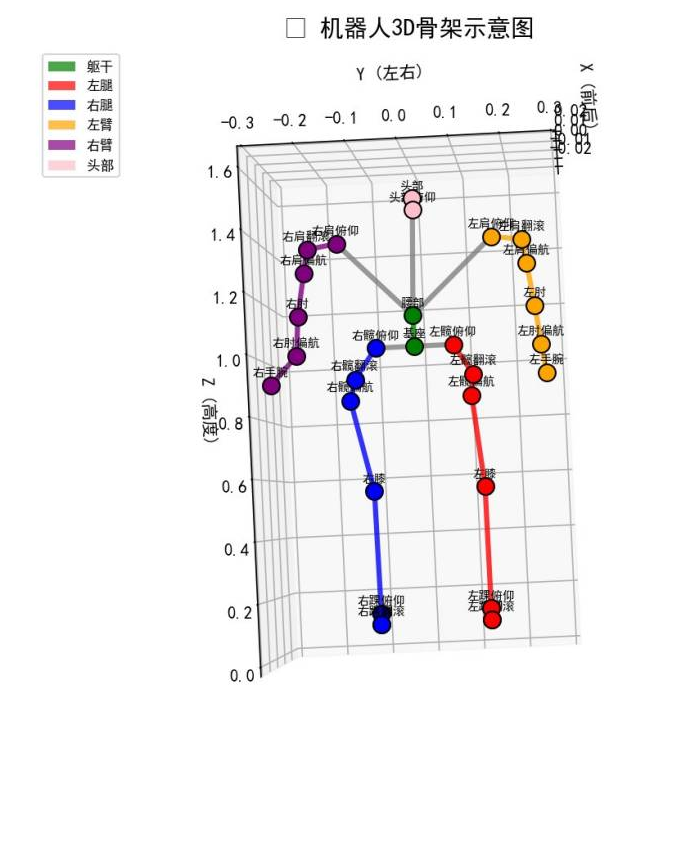

*原课件第 2 页左侧，裁取三维骨架及图例。*

先对照图中的坐标轴读位置：

| 坐标轴 | 课件标注 | 观察内容 |
|---|---|---|
| X | 前后 | 部件在前后方向的分布 |
| Y | 左右 | 左侧与右侧部件的分布 |
| Z | 高度 | 头、肩、躯干、腿和脚的上下位置 |

图中头部位于上方，躯干居中，肩部向两侧连接手臂，髋部向下连接腿。左右对称部件的高度接近，但在左右方向上分开。

读图时同时看点的名称与坐标轴，避免用屏幕上的“左边”判断机器人的左侧。三维视角变化会改变图像中的左右位置，部件名称仍对应机器人自身的左右侧。


## 3. 同一骨架的 X–Z 与 Y–Z 投影

课件把三维骨架进一步投影到两个平面，便于单独观察某两个方向。

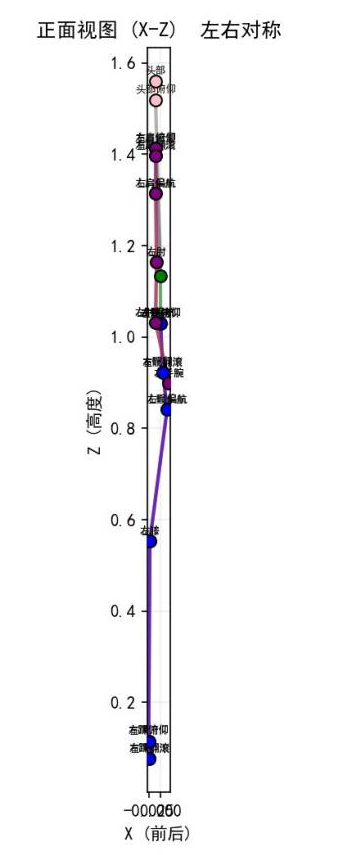

*原课件第 2 页中部：横轴 X（前后），纵轴 Z（高度）。*

X–Z 投影舍去了 Y 方向的信息。对于这张图中的对称姿态，左右对应部件的前后位置与高度接近，因此不少点和文字重叠。仅凭这张投影难以判断某个点属于左侧还是右侧。

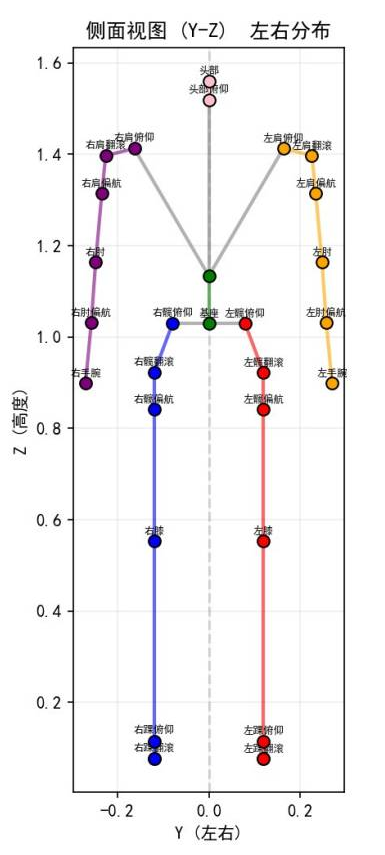

*原课件第 2 页右侧：横轴 Y（左右），纵轴 Z（高度）。*

Y–Z 投影舍去了 X 方向的信息，左右手臂和双腿的分布更清楚。它适合对照左右对应部件的高度及横向位置，前后差异则需要结合 X–Z 投影或三维图查看。

**原图标注说明：**课件将 X–Z 图题为“正面视图”，将 Y–Z 图题为“侧面视图”。按同页的 X 前后、Y 左右约定，沿前后方向看的正面投影通常是 Y–Z，沿左右方向看的侧面投影通常是 X–Z。原图保留，本篇按坐标轴名称解释两张图。

> 投影省略了一个方向。两点在某张投影中重合，不代表它们在三维空间中处于同一个位置。


## 4. 工程补充：相对位置与世界位置

以下说明与示例用于把课件中的位置关系对应到 MuJoCo，采用前两篇已核对的官方 T800 模型版本 `335c60e88772c26c7852d0abd6b3c7439037dd8f`，不是课件原代码。

### 4.1 坐标需要说明参照系

本篇把**绝对坐标**理解为世界坐标系中的位置。世界坐标系是场景使用的公共参照，机器人移动时，部件的世界位置会变化。

**相对坐标**必须说明相对于谁，以及按谁的坐标轴表达。例如，右肩相对于其父连杆的位置，与右肩相对于世界原点的位置是两组不同的数。

在 MJCF XML 中，`<body pos="...">` 描述 body 在参考姿态下相对于父 body 的位置。`<joint pos="...">` 描述关节锚点在其所属 body 坐标系中的位置，两者的参照系不同。

| 字段 | 位置含义 |
|---|---|
| `model.body_pos[body_id]` | 模型定义的 body 相对于父 body 的参考位置偏移 |
| `model.jnt_pos[joint_id]` | 模型定义的关节锚点在所属 body 内的局部位置 |
| `data.xpos[body_id]` | 当前姿态下 body 坐标系原点的世界位置 |
| `data.xanchor[joint_id]` | 当前姿态下关节锚点的世界位置 |

`body_pos` 属于模型结构，不能普遍当成运动过程中即时的相对位移。读取当前世界位置前，先调用 `mj_forward()`，使派生的位置数据与当前状态一致。

### 4.2 父坐标系发生旋转时，不能只相加

设父 body 的世界位置为 $\mathbf p_{WP}$，其局部坐标到世界坐标的旋转矩阵为 $R_{WP}$。子 body 原点在父坐标系中的当前位置为 $\mathbf p_{PB}$，则：

$$
\mathbf p_{WB} = \mathbf p_{WP} + R_{WP}\mathbf p_{PB}
$$

反过来，根据两者的世界位置得到父坐标系中的相对位置：

$$
\mathbf p_{PB} = R_{WP}^{\mathsf T}(\mathbf p_{WB}-\mathbf p_{WP})
$$

父坐标系与世界坐标系方向一致时，旋转矩阵为单位矩阵，位置关系才可简化为直接相加。一般情况下，两组世界位置相减得到的是按**世界坐标轴**表达的位移，还需要旋转才能按父坐标轴表达。

### 4.3 读取右肩的两种位置

沿用第 03、04 篇的 `t800-load` 练习目录、官方模型与 `.venv`，新建 `inspect_positions.py`。脚本默认读取同目录下官方仓库的 `assets/resource/t800.xml`，也支持 `--model` 指定其他位置的场景入口。

```python
import argparse
from pathlib import Path

import mujoco
import numpy as np

parser = argparse.ArgumentParser(description="读取 T800 相对位置与世界位置")
parser.add_argument(
    "--model", type=Path,
    default=Path(__file__).resolve().parent
    / "engineai_robotics_native_sdk/assets/resource/t800.xml",
)
args = parser.parse_args()
model = mujoco.MjModel.from_xml_path(str(args.model.expanduser().resolve()))
data = mujoco.MjData(model)
mujoco.mj_forward(model, data)

body_id = model.body("LINK_SHOULDER_PITCH_R").id
parent_id = int(model.body_parentid[body_id])
joint_id = model.joint("J18_SHOULDER_PITCH_R").id
parent_rotation = data.xmat[parent_id].reshape(3, 3)
relative_now = parent_rotation.T @ (
    data.xpos[body_id] - data.xpos[parent_id]
)

np.set_printoptions(precision=5, suppress=True)
print("parent:", model.body(parent_id).name)
print("body_pos:", model.body_pos[body_id])
print("parent_world:", data.xpos[parent_id])
print("body_world:", data.xpos[body_id])
print("relative_now:", relative_now)
print("joint_world:", data.xanchor[joint_id])
```

`data.xmat[parent_id]` 保存父 body 当前在世界中的姿态，`reshape(3, 3)` 将其读成旋转矩阵。脚本读取初始姿态，不推进仿真时间。

在 `t800-load` 目录的 PowerShell 中执行：

```powershell
.\.venv\Scripts\python.exe inspect_positions.py
```

本篇在 MuJoCo 3.4.0 中实际运行上述脚本，父 body 名称为 `LINK_WAIST_YAW`，读取结果如下，长度单位为米：

| 读取项 | 本次初始姿态下的 `(x, y, z)` |
|---|---|
| `body_pos`，模型参考偏移 | `(-0.01100, -0.16303, 0.27889)` |
| `parent_world`，父 body 世界位置 | `(0.00000, 0.00000, 1.13384)` |
| `body_world`，右肩 body 世界位置 | `(-0.01100, -0.16303, 1.41273)` |
| `relative_now`，当前按父坐标轴表达的相对位置 | `(-0.01100, -0.16303, 0.27889)` |
| `joint_world`，右肩俯仰关节锚点世界位置 | `(-0.01100, -0.16303, 1.41273)` |

这时父 body 的坐标轴与世界坐标轴方向一致，右肩的世界高度为 `1.13384 + 0.27889 = 1.41273`。`relative_now` 与 `body_pos` 在本次姿态下一致，不能据此省略其他姿态下的坐标变换。

右肩关节的局部锚点恰好为 `pos="0 0 0"`，所以这里 `joint_world` 与 `body_world` 相同。其他关节的锚点可能偏离 body 原点，要按目标对象选择字段。这组精确读数来自所注明版本的模型，不是从课件图中估算的固定数值。


## 5. 本课检查与补充参考

完成本节，应能根据坐标轴读懂骨架与投影，说明某个位置相对于哪个坐标系，并区分模型参考偏移、当前 body 世界位置与关节锚点世界位置。

补充脚本已在官方 T800 模型中实际运行并核对读数。本篇只检查位置关系，没有验证机器人运动或真实硬件。

- [本篇版本的 T800 连杆与关节定义](https://github.com/engineai-robotics/engineai_robotics_native_sdk/blob/335c60e88772c26c7852d0abd6b3c7439037dd8f/assets/resource/robot/t800/xml/serial_links.xml)。
- [MuJoCo 3.4.0：body 的 pos 参照系](https://mujoco.readthedocs.io/en/3.4.0/XMLreference.html#body-pos)。
- [MuJoCo 3.4.0：joint 的 pos 参照系](https://mujoco.readthedocs.io/en/3.4.0/XMLreference.html#body-joint-pos)。
- [MuJoCo 3.4.0：mjData 位置与姿态字段](https://mujoco.readthedocs.io/en/3.4.0/APIreference/APItypes.html#mjdata)。
- [MuJoCo 3.4.0：mj_forward](https://mujoco.readthedocs.io/en/3.4.0/APIreference/APIfunctions.html#mj-forward)。
